# Baseline Evaluation & Model Predictions

**Project:** Spatio-Temporal Machine Learning for Urban Traffic Congestion Prediction and Dynamic Risk Mapping

**Dataset:** PeMS04 (Caltrans District 4, San Francisco Bay Area)

**Models:** Persistence Baseline vs Spatio-Temporal Forecasting

In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 11

# Paths
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
PROCESSED_DIR = os.path.join(PROJECT_ROOT, 'data', 'processed')
METRICS_DIR = os.path.join(PROJECT_ROOT, 'outputs', 'metrics')
PRED_DIR = os.path.join(PROJECT_ROOT, 'outputs', 'predictions')
FIG_DIR = os.path.join(PROJECT_ROOT, 'outputs', 'figures')

print('Project Root:', PROJECT_ROOT)

Project Root: C:\Users\Lenovo\OneDrive\Desktop\AUCML\traffic-congestion-ml


## 1. Load Processed Test Data and Scaler

In [2]:
# Load test data and normalization scaler
test_x = np.load(os.path.join(PROCESSED_DIR, 'test_x.npy'))
test_y = np.load(os.path.join(PROCESSED_DIR, 'test_y.npy'))
scaler = np.load(os.path.join(PROCESSED_DIR, 'scaler.npz'))
mean_val = float(scaler['mean'])
std_val = float(scaler['std'])

print(f'Test Input  (test_x): {test_x.shape} (samples, history_steps=12, sensors=307)')
print(f'Test Target (test_y): {test_y.shape} (samples, forecast_steps=12, sensors=307)')
print(f'Scaler: Mean = {mean_val:.2f}, Std = {std_val:.2f}')

# Convert test target back to original scale (vehicles per 5 minutes)
test_y_orig = test_y * std_val + mean_val
print(f'Original Scale Range: [{test_y_orig.min():.1f}, {test_y_orig.max():.1f}] veh/5min')

Test Input  (test_x): (3394, 12, 307) (samples, history_steps=12, sensors=307)
Test Target (test_y): (3394, 12, 307) (samples, forecast_steps=12, sensors=307)
Scaler: Mean = 207.23, Std = 156.48
Original Scale Range: [0.0, 912.0] veh/5min


## 2. Load Persistence Baseline Predictions & Metrics

In [3]:
# Load metrics json
with open(os.path.join(METRICS_DIR, 'persistence_metrics.json')) as f:
    metrics_data = json.load(f)

# Load saved predictions
pred_npz = np.load(os.path.join(PRED_DIR, 'persistence_predictions.npz'))
y_pred_orig = pred_npz['predictions']

print('Persistence Baseline Predictions shape:', y_pred_orig.shape)
print('\nEvaluated Metrics (Original Scale - veh/5min):')
h_dict = metrics_data['metrics']['horizons']

results_table = []
for h_key, h_val in h_dict.items():
    results_table.append({
        'Horizon': h_val['label'],
        'Minutes': h_val['horizon_minutes'],
        'MAE (veh/5min)': round(h_val['mae'], 2),
        'RMSE (veh/5min)': round(h_val['rmse'], 2)
    })

overall = metrics_data['metrics']['overall']
results_table.append({
    'Horizon': 'Overall (All 12 Steps)',
    'Minutes': 60,
    'MAE (veh/5min)': round(overall['mae'], 2),
    'RMSE (veh/5min)': round(overall['rmse'], 2)
})

df_results = pd.DataFrame(results_table)
display(df_results)

Persistence Baseline Predictions shape: (3394, 12, 307)

Evaluated Metrics (Original Scale - veh/5min):


,Horizon,Minutes,MAE (veh/5min),RMSE (veh/5min)
0,Horizon 3 (15 min),15,24.92,39.00
1,Horizon 6 (30 min),30,30.28,45.87
2,Horizon 12 (60 min),60,42.38,61.67
3,Overall (All 12 Steps),60,31.56,48.36


## 3. Actual vs Predicted Traffic Curves

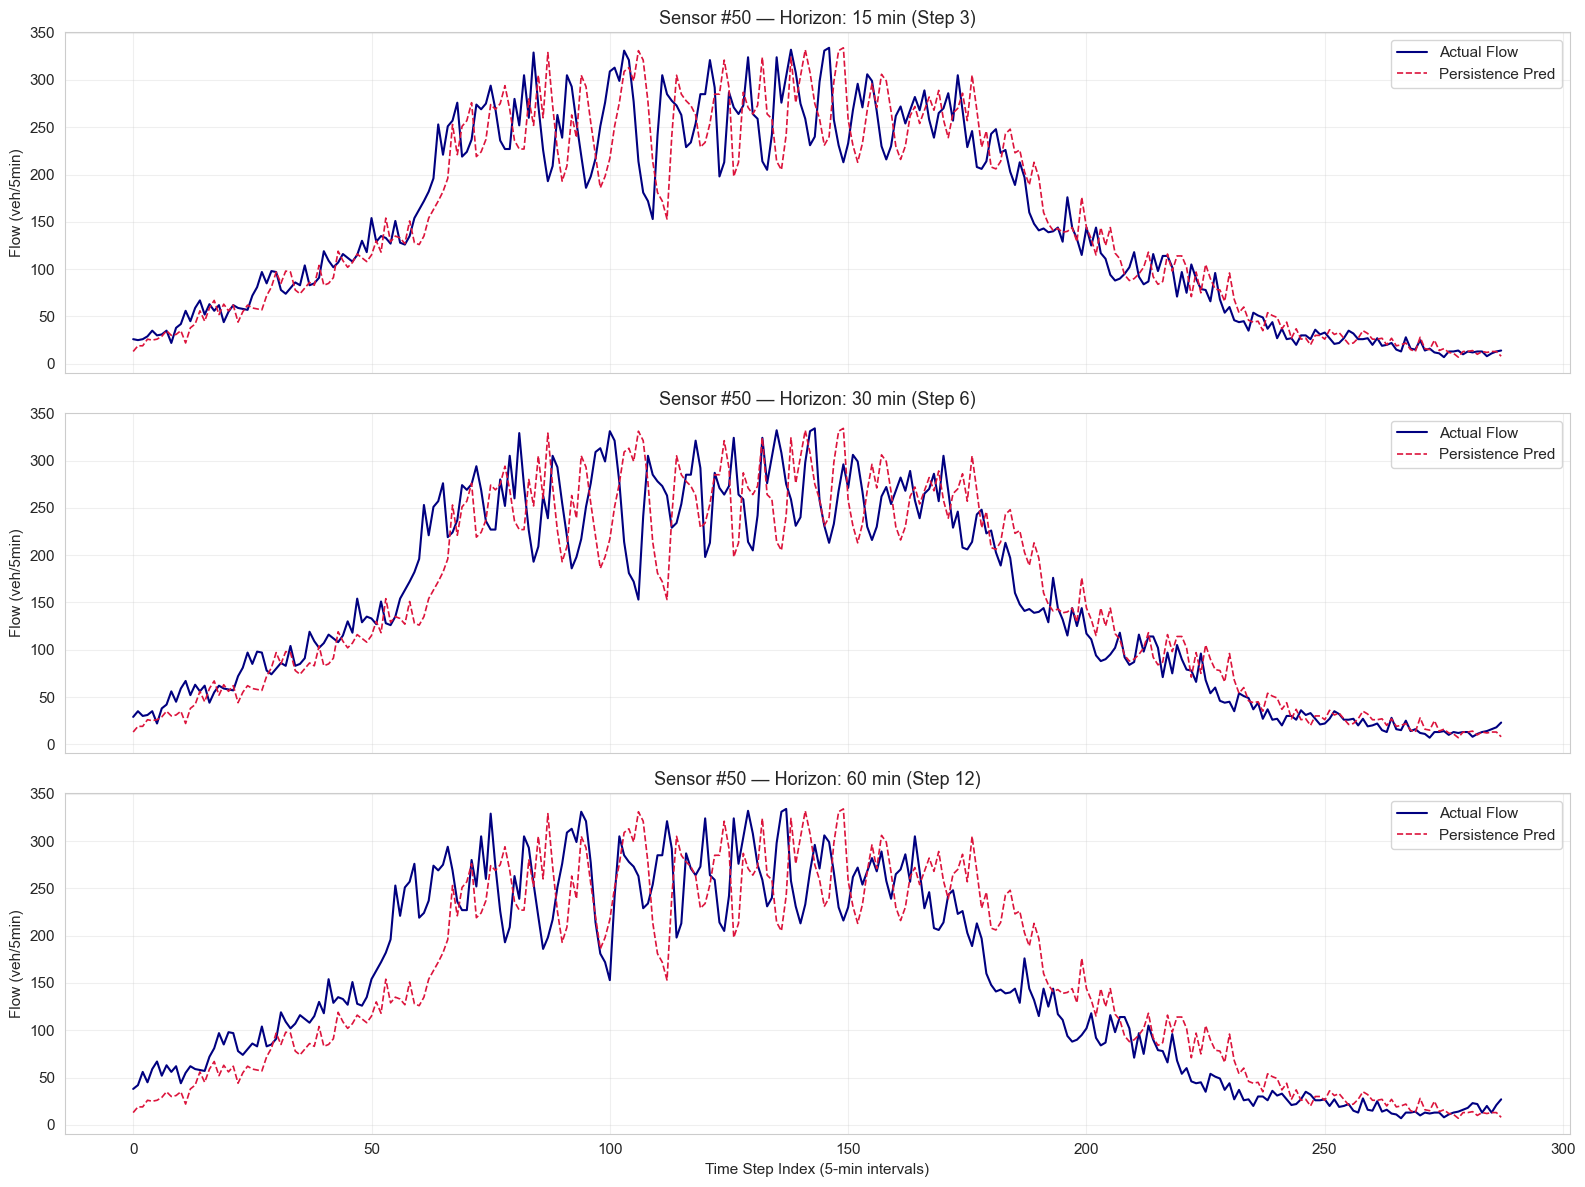

Saved: outputs/figures/actual_vs_predicted_persistence.png


In [4]:
# Visualize Actual vs Predicted for representative sensors across horizons
sensors_to_plot = [10, 100, 200]
horizons = [(2, '15 min (Step 3)'), (5, '30 min (Step 6)'), (11, '60 min (Step 12)')]
n_steps_plot = 288  # 1 full day of test samples (24h * 12 samples/h)

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

sensor_id = 50
for idx, (h_step, h_name) in enumerate(horizons):
    act = test_y_orig[:n_steps_plot, h_step, sensor_id]
    prd = y_pred_orig[:n_steps_plot, h_step, sensor_id]
    
    axes[idx].plot(act, label='Actual Flow', color='navy', linewidth=1.5)
    axes[idx].plot(prd, label=f'Persistence Pred', color='crimson', linestyle='--', linewidth=1.2)
    axes[idx].set_title(f'Sensor #{sensor_id} — Horizon: {h_name}', fontsize=13)
    axes[idx].set_ylabel('Flow (veh/5min)')
    axes[idx].legend(loc='upper right')
    axes[idx].grid(True, alpha=0.3)

axes[-1].set_xlabel('Time Step Index (5-min intervals)')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'actual_vs_predicted_persistence.png'), dpi=150)
plt.show()
print('Saved: outputs/figures/actual_vs_predicted_persistence.png')

## 4. Horizon Degradation Analysis

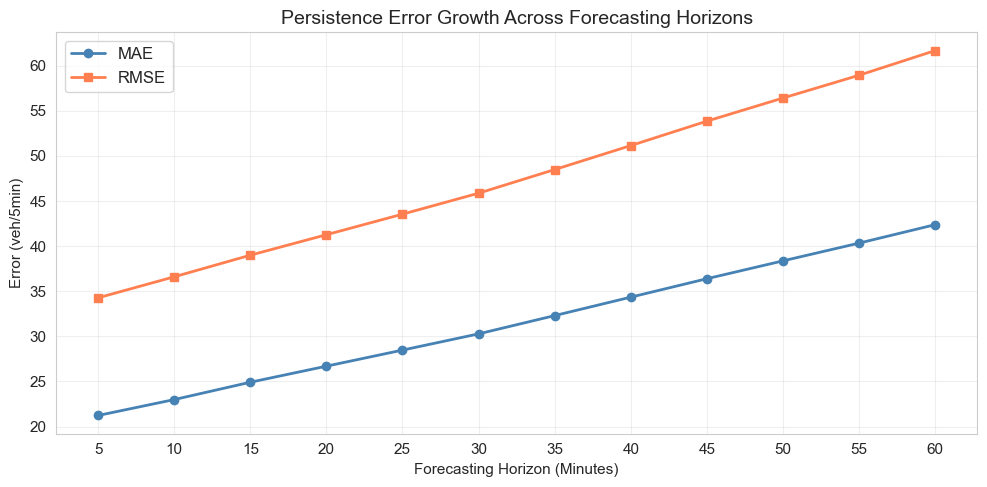

Saved: outputs/figures/horizon_error_growth.png


In [5]:
# Plot error growth over prediction horizon
steps = np.arange(1, 13)
step_maes = []
step_rmses = []

for s in range(12):
    yt = test_y_orig[:, s, :]
    yp = y_pred_orig[:, s, :]
    mask = yt > 0
    mae = np.mean(np.abs(yt[mask] - yp[mask]))
    rmse = np.sqrt(np.mean((yt[mask] - yp[mask])**2))
    step_maes.append(mae)
    step_rmses.append(rmse)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(steps * 5, step_maes, marker='o', color='steelblue', linewidth=2, label='MAE')
ax1.plot(steps * 5, step_rmses, marker='s', color='coral', linewidth=2, label='RMSE')
ax1.set_title('Persistence Error Growth Across Forecasting Horizons', fontsize=14)
ax1.set_xlabel('Forecasting Horizon (Minutes)')
ax1.set_ylabel('Error (veh/5min)')
ax1.set_xticks(steps * 5)
ax1.legend(fontsize=12)
ax1.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'horizon_error_growth.png'), dpi=150)
plt.show()
print('Saved: outputs/figures/horizon_error_growth.png')

## 5. Congestion Risk Mapping

Congestion Classification Thresholds:
  q25: 83.0 veh/5min
  q50: 179.0 veh/5min
  q75: 315.0 veh/5min


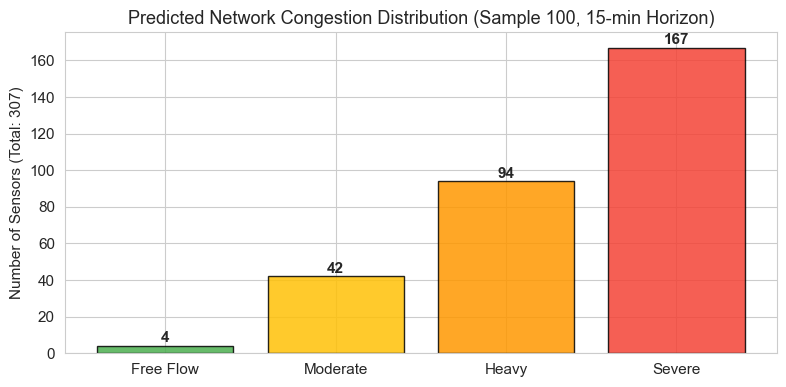

Saved: outputs/figures/congestion_distribution_sample.png


In [6]:
# Load congestion classification thresholds
with open(os.path.join(METRICS_DIR, 'congestion_thresholds.json')) as f:
    cong_data = json.load(f)

thresholds = cong_data['thresholds']
print('Congestion Classification Thresholds:')
for k, v in thresholds.items():
    print(f'  {k}: {v:.1f} veh/5min')

# Classify a test time step (e.g. morning rush hour)
sample_idx = 100
horizon_step = 2  # 15 min
flows = y_pred_orig[sample_idx, horizon_step, :]

categories = np.zeros(len(flows), dtype=int)
categories[flows >= thresholds['q25']] = 1
categories[flows >= thresholds['q50']] = 2
categories[flows >= thresholds['q75']] = 3

cat_labels = ['Free Flow', 'Moderate', 'Heavy', 'Severe']
cat_colors = ['#4CAF50', '#FFC107', '#FF9800', '#F44336']

counts = pd.Series([cat_labels[c] for c in categories]).value_counts().reindex(cat_labels, fill_value=0)

plt.figure(figsize=(8, 4))
plt.bar(counts.index, counts.values, color=cat_colors, edgecolor='black', alpha=0.85)
plt.title(f'Predicted Network Congestion Distribution (Sample {sample_idx}, 15-min Horizon)', fontsize=13)
plt.ylabel('Number of Sensors (Total: 307)')
for i, v in enumerate(counts.values):
    plt.text(i, v + 2, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'congestion_distribution_sample.png'), dpi=150)
plt.show()
print('Saved: outputs/figures/congestion_distribution_sample.png')